In [1]:
# Time Series Prediction - decomposition, stationarity, Holt-Winters, SARIMA
# Datasets:
#   - Airline Passengers: ../Datasets/AirPassengers.csv
#     https://www.kaggle.com/datasets/rakannimer/air-passengers
#   - Store Sales - Time Series Forecasting (optional, Part 2): ../Datasets/store_sales_train.csv
#     https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data
#
# Needs: pip install statsmodels
#
# Golden rule of time series: NEVER shuffle or randomly split the data.
# Train on the past, test on the future - always in time order.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX


(144, 2)
     Month  #Passengers
0  1949-01          112
1  1949-02          118
2  1949-03          132
3  1949-04          129
4  1949-05          121
Month          0
#Passengers    0
dtype: int64


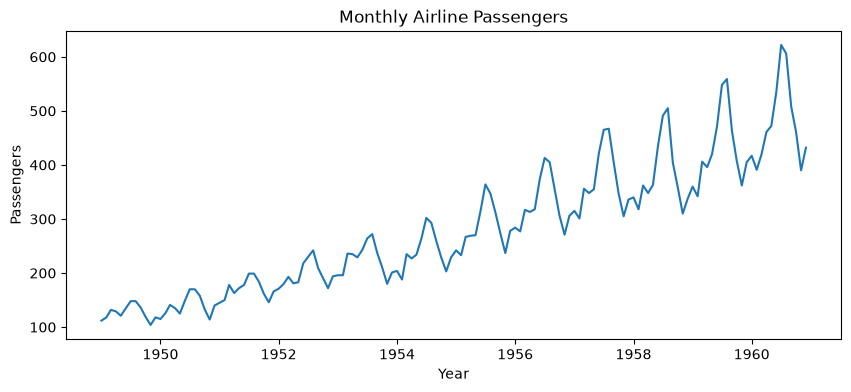

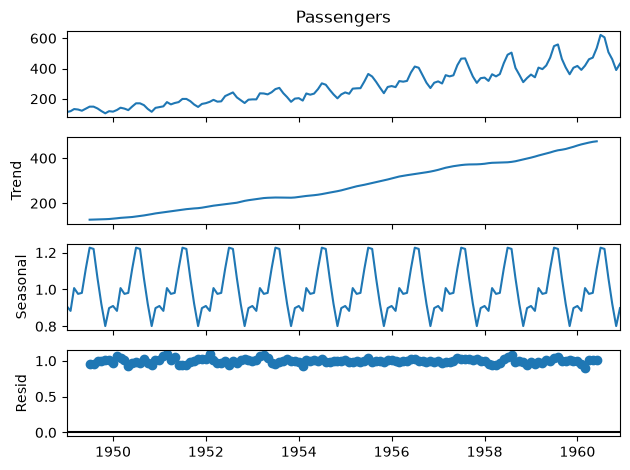

ADF statistic: 0.8153688792060576
p-value: 0.9918802434376411

After log + first difference:
p-value: 0.07112054815086186


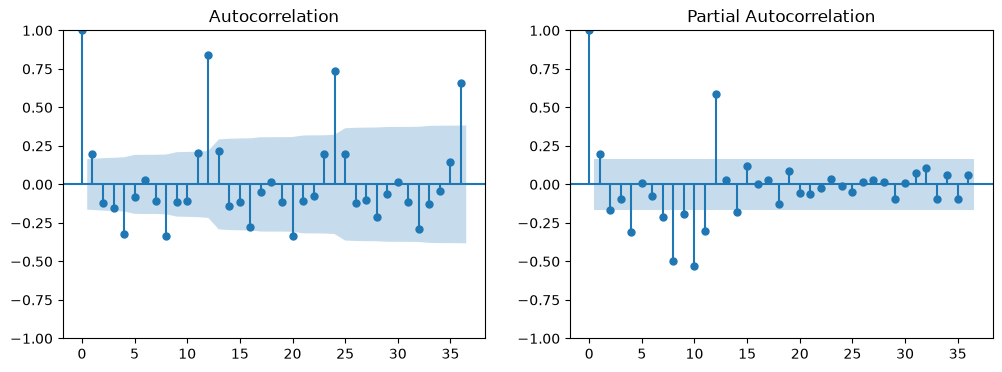

Train: 1949-01-01 -> 1958-12-01
Test : 1959-01-01 -> 1960-12-01
            Model     MAE    RMSE  MAPE %
2    Holt-Winters   28.98   32.49    6.39
3          SARIMA   36.38   40.13    7.85
1  Seasonal Naive   71.25   76.99   15.52
0           Naive  115.25  137.33   23.58


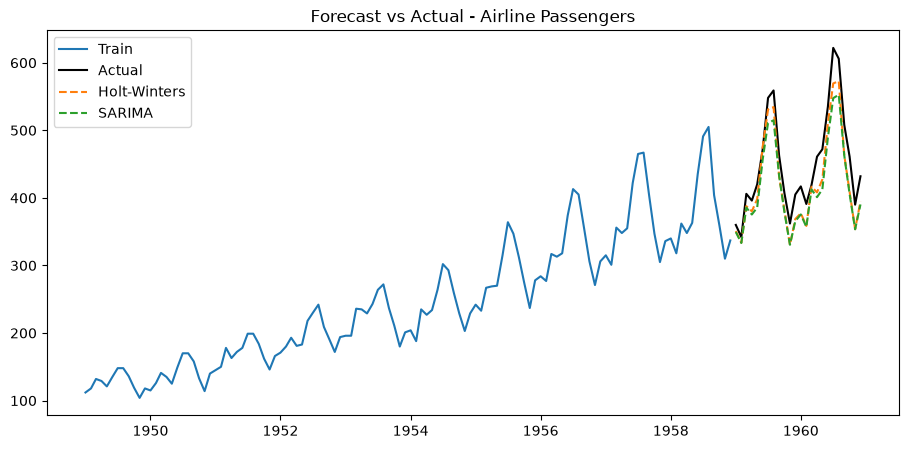

1961-01-01    451.0
1961-02-01    427.0
1961-03-01    482.0
1961-04-01    493.0
1961-05-01    511.0
1961-06-01    585.0
1961-07-01    673.0
1961-08-01    672.0
1961-09-01    561.0
1961-10-01    499.0
1961-11-01    432.0
1961-12-01    480.0
Freq: MS, Name: predicted_mean, dtype: float64


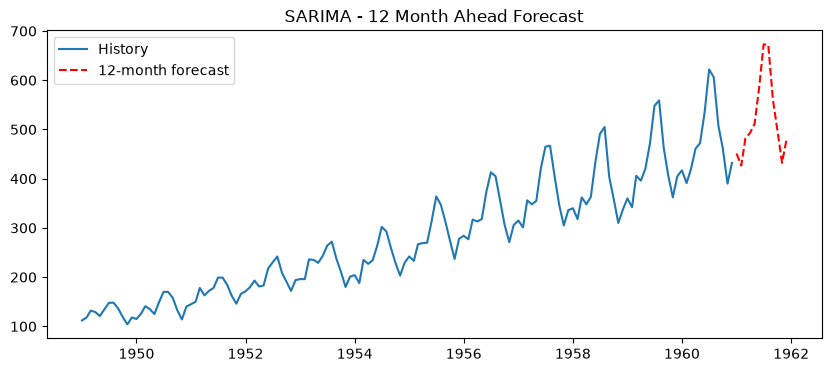

In [2]:
# ============================================================
# PART 1 - Airline Passengers (monthly, 1949-1960)
# ============================================================

df = pd.read_csv("../Datasets/AirPassengers.csv")

print(df.shape)
print(df.head())
print(df.isnull().sum())

# ---- 1. Set up the datetime index ----
df["Month"] = pd.to_datetime(df["Month"])
df = df.set_index("Month")
df = df.rename(columns={"#Passengers": "Passengers"})
df.index.freq = "MS"     # tell pandas this is Month-Start data

series = df["Passengers"]

# ---- 2. Plot the raw series ----
plt.figure(figsize=(10, 4))
plt.plot(series)
plt.title("Monthly Airline Passengers")
plt.xlabel("Year")
plt.ylabel("Passengers")
plt.show()

# two things stand out: an upward TREND, and a repeating yearly SEASONAL pattern
# whose swings get bigger as the level rises (multiplicative seasonality)

# ---- 3. Decompose into trend + seasonal + residual ----
decomp = seasonal_decompose(series, model="multiplicative", period=12)
decomp.plot()
plt.show()

# ---- 4. Stationarity check (ADF test) ----
# most classical models (ARIMA) need a stationary series - constant mean/variance over time
adf_result = adfuller(series)
print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])
# p > 0.05 -> NOT stationary (can't reject the presence of a trend)

# make it stationary: log to stabilise the growing variance, then difference to remove trend
series_log = np.log(series)
series_diff = series_log.diff().dropna()

print("\nAfter log + first difference:")
print("p-value:", adfuller(series_diff)[1])

# ---- 5. ACF / PACF plots (help choose ARIMA orders) ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(series_diff, lags=36, ax=axes[0])
plot_pacf(series_diff, lags=36, ax=axes[1])
plt.show()

# the spike at lag 12 in the ACF confirms yearly seasonality

# ---- 6. Chronological train/test split - last 24 months held out ----
train = series.iloc[:-24]
test = series.iloc[-24:]

print("Train:", train.index.min().date(), "->", train.index.max().date())
print("Test :", test.index.min().date(), "->", test.index.max().date())
# small helper values for evaluation - kept as plain code, not a function
results = {}

# ---- 7. Baseline 1: Naive forecast (tomorrow = today) ----
naive_pred = pd.Series(train.iloc[-1], index=test.index)

# ---- 8. Baseline 2: Seasonal naive (this month = same month last year) ----
seasonal_naive_pred = pd.Series(
    train.iloc[-12:].values.tolist() * 2, index=test.index
)

# ---- 9. Holt-Winters (Exponential Smoothing with trend + seasonality) ----
hw_model = ExponentialSmoothing(
    train, trend="add", seasonal="mul", seasonal_periods=12
).fit()
hw_pred = hw_model.forecast(24)

# ---- 10. SARIMA on log scale ----
# (1,1,1)(1,1,1,12) is a standard starting point for monthly seasonal data
sarima_model = SARIMAX(
    np.log(train), order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)
).fit(disp=False)
sarima_pred_log = sarima_model.forecast(24)
sarima_pred = np.exp(sarima_pred_log)     # back to the original passenger scale

# ---- 11. Evaluate all models ----
predictions = {
    "Naive": naive_pred,
    "Seasonal Naive": seasonal_naive_pred,
    "Holt-Winters": hw_pred,
    "SARIMA": sarima_pred,
}

rows = []
for name, pred in predictions.items():
    mae = np.mean(np.abs(test.values - pred.values))
    rmse = np.sqrt(np.mean((test.values - pred.values) ** 2))
    mape = np.mean(np.abs((test.values - pred.values) / test.values)) * 100
    rows.append({"Model": name, "MAE": mae, "RMSE": rmse, "MAPE %": mape})

results_df = pd.DataFrame(rows).sort_values("RMSE")
print(results_df.round(2))

# Holt-Winters and SARIMA should clearly beat both naive baselines.
# If a fancy model can't beat seasonal naive, it isn't earning its complexity.

# ---- 12. Plot forecasts against actual ----
plt.figure(figsize=(11, 5))
plt.plot(train, label="Train")
plt.plot(test, label="Actual", color="black")
plt.plot(hw_pred, label="Holt-Winters", linestyle="--")
plt.plot(sarima_pred, label="SARIMA", linestyle="--")
plt.title("Forecast vs Actual - Airline Passengers")
plt.legend()
plt.show()

# ---- 13. Forecast the genuine future (refit on ALL data, predict next 12 months) ----
final_model = SARIMAX(
    np.log(series), order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)
).fit(disp=False)
future = np.exp(final_model.forecast(12))
print(future.round(0))

plt.figure(figsize=(10, 4))
plt.plot(series, label="History")
plt.plot(future, label="12-month forecast", linestyle="--", color="red")
plt.title("SARIMA - 12 Month Ahead Forecast")
plt.legend()
plt.show()
    

(3000888, 6)
   id       date  store_nbr      family  sales  onpromotion
0   0 2013-01-01          1  AUTOMOTIVE    0.0            0
1   1 2013-01-01          1   BABY CARE    0.0            0
2   2 2013-01-01          1      BEAUTY    0.0            0
3   3 2013-01-01          1   BEVERAGES    0.0            0
4   4 2013-01-01          1       BOOKS    0.0            0
Missing days: 4


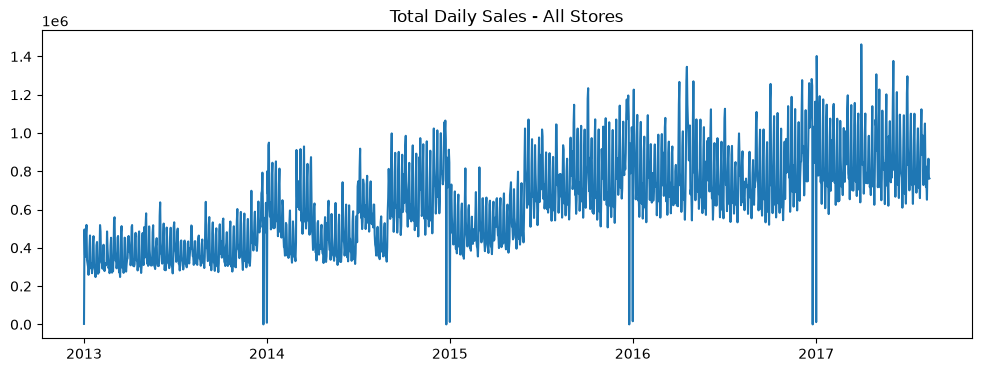

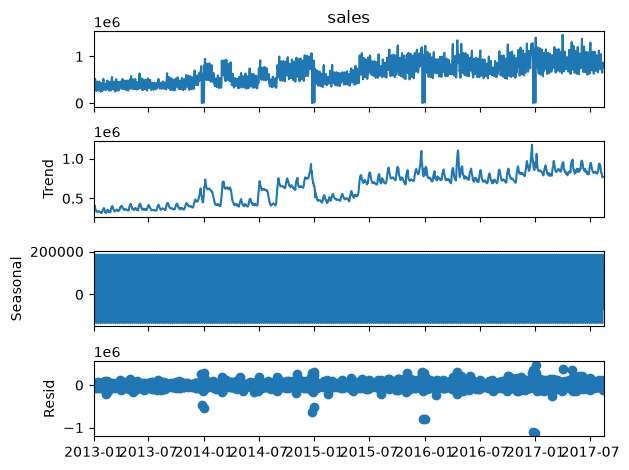

Holt-Winters  MAE: 59,840   MAPE: 6.96%


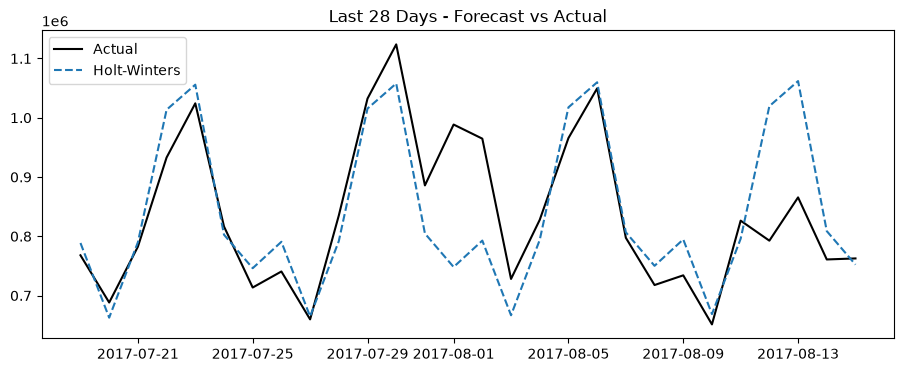

In [4]:
# ============================================================
# PART 2 (optional) - Store Sales Time Series Forecasting
# ============================================================
# The raw file is large (~3 million rows: 54 stores x 33 product families x ~1700 days).
# Simplest sensible starting point: add everything up into ONE daily total-sales series.

#sales = pd.read_csv("../Datasets/store_sales_train.csv", parse_dates=["date"])
sales = pd.read_csv(r"C:\Users\syin\Downloads\store-sales-time-series-forecasting (1)\train.csv", parse_dates=["date"])

print(sales.shape)
print(sales.head())

daily = sales.groupby("date")["sales"].sum()
daily = daily.asfreq("D")            # make sure every calendar day is present

print("Missing days:", daily.isnull().sum())
# Christmas Day (Dec 25) is missing from this dataset - stores were closed
daily = daily.fillna(0)

plt.figure(figsize=(12, 4))
plt.plot(daily)
plt.title("Total Daily Sales - All Stores")
plt.show()

# ---- Weekly seasonality this time (period = 7 days) ----
decomp_sales = seasonal_decompose(daily, model="additive", period=7)
decomp_sales.plot()
plt.show()
# ---- Chronological split - hold out last 28 days ----
train_s = daily.iloc[:-28]
test_s = daily.iloc[-28:]

hw_sales = ExponentialSmoothing(
    train_s, trend="add", seasonal="add", seasonal_periods=7
).fit()
hw_sales_pred = hw_sales.forecast(28)

mae = np.mean(np.abs(test_s.values - hw_sales_pred.values))
mape = np.mean(np.abs((test_s.values - hw_sales_pred.values) / test_s.values)) * 100
print(f"Holt-Winters  MAE: {mae:,.0f}   MAPE: {mape:.2f}%")

plt.figure(figsize=(11, 4))
plt.plot(test_s, label="Actual", color="black")
plt.plot(hw_sales_pred, label="Holt-Winters", linestyle="--")
plt.title("Last 28 Days - Forecast vs Actual")
plt.legend()
plt.show()

# next steps to improve this (good portfolio extensions):
#   - use onpromotion, holidays and oil price as extra features (SARIMAX or ML models)
#   - forecast per store / product family instead of one grand total